This is for downloading the Ogino 2026 Kaguya dataset (April 24, 2009) and attempting to recreate Ogino 2026's figure 2.


To install the dataset from Zenodo from terminal:

pip install zenodo_get zenodo_get 

17394182 -o kaguya_data

First, we look at ESA-S1 (Electron Spectrum Analyser) in Kaguya's PACE package. in High Time Resolution Mode, ESA-S1 produces a full 3D distribution every 2s covering 32 energy steps × 4 polar angles × 16 azimuthal angles. Data is already processed and split into half-sweeps (files are 1 second apart, so time resolution is doubled and energy resolution is halved; 16 energy steps per half-sweep) and rotated into SSE.

Angular width: each full sweep has angular width of 90/4 = 360/16 = 22.5 degrees, so each half-sweep has approx angular width in the Vz-Vy plane of of 22.5 / 2 = 11.25 degrees.

Source: Saito et al. (2010)

In [127]:
import numpy as np

# electron mass and charge
me, e = 9.109e-31, 1.602e-19

# load data starting from 2009-04-24-22:55:24
d = np.loadtxt('kaguya_data/esa1_df_20090424225524.txt')

# load columns 0-2 as x, y, z velocity components and convert from km/s to m/s
v = d[:, :3] * 1e3

# load column 3 separately as distribution function (phase-space density) with units s^3/m^6
f = d[:, 3]

# calculate the kinetic energy of each row in eV
E = 0.5 * me * np.sum(v**2, axis=1) / e

print(d.shape) # file layout dimensions
print(E[:200].round(1)) # array of first few energies, rounded

(224, 4)
[ 24.1  39.4  63.  101.3  23.7  38.7  61.9  99.5  23.6  38.5  61.7  99.1
  23.1  37.8  60.4  97.2  24.1  39.3  62.9 101.1  23.7  38.6  61.8  99.3
  23.5  38.4  61.5  98.8  23.1  37.7  60.3  96.9  24.   39.2  62.7 100.8
  23.6  38.4  61.5  98.9  23.4  38.2  61.2  98.3  23.   37.5  60.   96.5
  23.8  38.9  62.3 100.1  23.4  38.2  61.1  98.2  23.2  37.9  60.7  97.6
  22.8  37.2  59.5  95.7  23.9  39.   62.5 100.4  23.4  38.3  61.2  98.4
  23.3  38.1  60.9  97.9  22.9  37.3  59.7  96.   23.8  38.9  62.2 100.
  23.4  38.2  61.1  98.2  23.2  37.9  60.7  97.6  22.8  37.2  59.5  95.7
  23.5  38.4  61.5  98.8  23.1  37.7  60.3  96.8  22.9  37.4  59.9  96.3
  22.5  36.8  58.8  94.5  23.6  38.5  61.5  98.9  23.1  37.7  60.4  97.1
  23.   37.6  60.1  96.6  22.6  36.9  59.   94.8  23.5  38.4  61.5  98.8
  23.1  37.7  60.3  96.9  22.9  37.4  59.9  96.2  22.5  36.7  58.8  94.5
  23.8  38.9  62.2 100.   23.3  38.1  61.   98.   23.2  37.9  60.6  97.5
  22.8  37.2  59.5  95.6  23.8  38.9  62.2 

For this file, we obtain that there are 224 rows with 4 energies, around 24, 38, 62 and 98 eV. Therefore there are 224/4 = 56 outlook directions (out of 64... why are 8 missing?). Therefore the instrument bins electrons into these four steps, with energy stepping ratio of approx 1.6.

Now attempt to recreate Fig 2 from Ogino 2025. Looking at LMAG data for magnetic field:

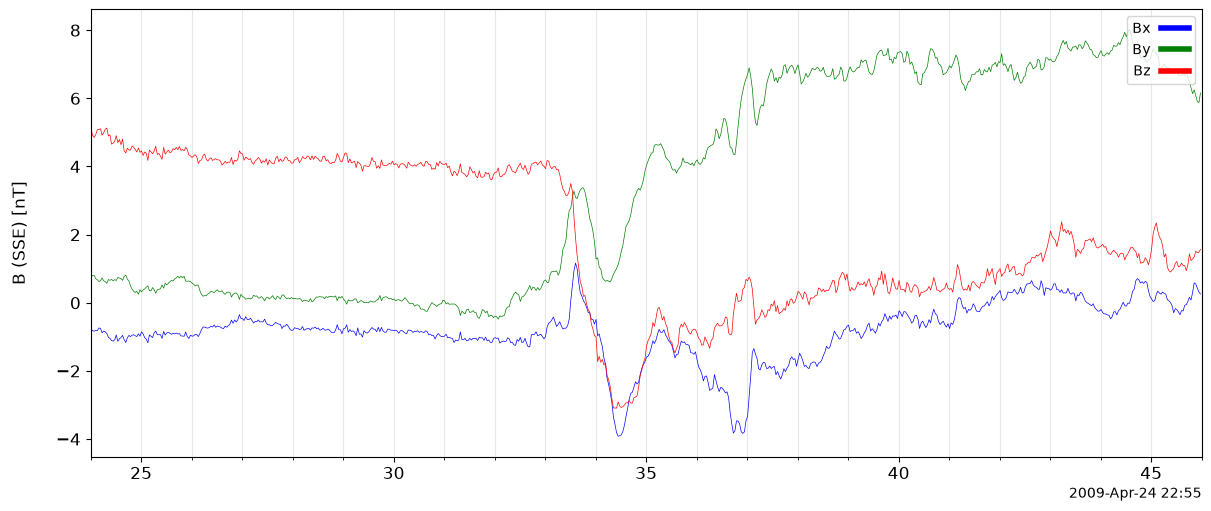

In [128]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pyspedas import time_double, store_data, tplot, options

fn = 'kaguya_data/lmag_32Hz_Bsse_20090424225120-20090424230400.txt'
tstr = np.loadtxt(fn, usecols=0, dtype=str) # column 0: time string
B = np.loadtxt(fn, usecols=(1, 2, 3)) # columns 1, 2, 3: Bx, By, Bz (nT)
t = np.array(time_double(tstr))

store_data('kgy_lmag_sse', data={'x': t, 'y': B})
options('kgy_lmag_sse', 'legend_names', ['Bx', 'By', 'Bz'])
options('kgy_lmag_sse', 'ytitle', 'B (SSE) [nT]')

fig, ax = tplot('kgy_lmag_sse',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)

ax.xaxis.set_minor_locator(mdates.SecondLocator()) # a tick every second
ax.grid(which='both', axis='x', alpha=0.3) # vertical grid lines on all ticks
plt.show()

recall that store_data creates a tplot variable, where time array is paired with data array and stored in pySPEDAS memory under some name. options attaches plotting settings to stored variable.

Add also total B magnitude:

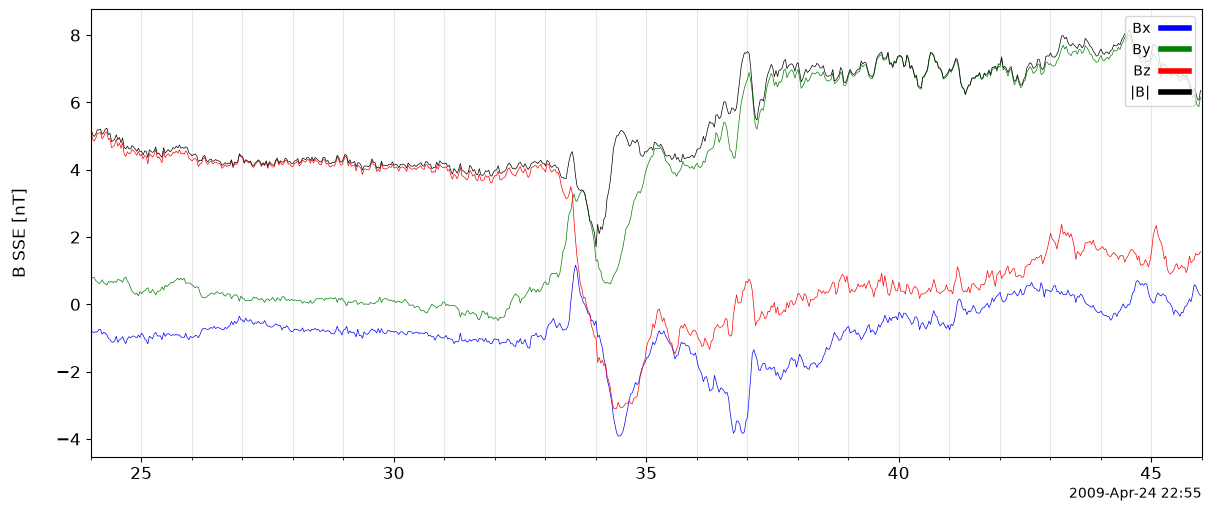

In [129]:
Bmag = np.linalg.norm(B, axis=1) #average across each row 
Ball = np.column_stack([B, Bmag])

store_data('kgy_lmag_sse_all', data={'x': t, 'y': Ball})
options('kgy_lmag_sse_all', 'legend_names', ['Bx', 'By', 'Bz', '|B|'])
options('kgy_lmag_sse_all', 'ytitle', 'B SSE [nT]')

fig, ax = tplot('kgy_lmag_sse_all',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)

ax.xaxis.set_minor_locator(mdates.SecondLocator())
ax.grid(which='both', axis='x', alpha=0.3)
plt.show()

Good agreement with Ogino 2026 fig. 2(i). Ogino et al. suggest that the |B| dip is correlated with field rotation and the Bx spike around 37 s is correlated with the flux rope. We also observe the strong perturbed field after the flux rope. 

Next we attempt to plot the same B field rotated to LMN coordinates (N: normal to sheet, L: along sheet, M: orthogonal third axis out of the plane along which current flows). The paper builds the coordinates using the cross-product method. First we determine the shearing angle between B1 (field before sheet) and B2 (field after the sheet):

In [130]:
# define sampling window for some range [t0, t1] and calculate mean Bx, y, z
def window_mean(t, B, t0, t1):
    m = (t >= time_double(t0)) & (t < time_double(t1))
    return B[m].mean(axis=0)

#set B1 and B2 as B values just before and after (guessed interval, paper not stated)
B1 = window_mean(t, B, '2009-04-24/22:55:31.5', '2009-04-24/22:55:32.0')
B2 = window_mean(t, B, '2009-04-24/22:55:39.0', '2009-04-24/22:55:39.5')

# find shearing angle before two fields: 
cos_shear = B1 @ B2 / (np.linalg.norm(B1) * np.linalg.norm(B2))
shear = np.degrees(np.arccos(cos_shear))

# normalise orthogonal N vector:
N = np.cross(B1, B2)
N = N / np.linalg.norm(N)

print('B1:', B1.round(2), ' B2', B2.round(2))
print('shear:', shear.round(2), 'deg')
print('N:', N.round(2))

B1: [-1.07 -0.32  3.77]  B2 [-0.82  6.9   0.51]
shear: 88.8 deg
N: [-0.96 -0.09 -0.28]


We obtain a shear angle of 88.8 degrees and an N vector of [-0.96 -0.09 -0.28]. This matches the results obtained by Ogino et al. to within 1 degree, and variance probably comes from difference in window choice.

Now we find L with minimum variance analysis.

Using a lagrangian multiplier to maximise variance, we obtain an EVP and find that each e-value is the variance along the corresponding e-vector:

In [131]:
m = (t >= time_double('2009-04-24/22:55:32')) & (t < time_double('2009-04-24/22:55:39'))
Bcs = B[m] # samples inside the crossing

dB = Bcs - Bcs.mean(axis=0) # subtract the mean field: B - <B>
M_cov = dB.T @ dB / len(dB) # covariance matrix: M_jk = <dB_j dB_k>

lam, vec = np.linalg.eigh(M_cov) # eigenvalues and eigenvectors
L_mva = vec[:, -1] # eigenvector with the largest eigenvalue

L_cross_N = np.cross(L_mva, N)

print('eigenvalue:', lam.round(3))
print('L_mva:', L_mva.round(2))
print('cross product with N:', L_cross_N)
print('ratio mid/min:', (lam[1] / lam[0]).round(1))

eigenvalue: [0.613 3.068 7.424]
L_mva: [-0.17  0.79 -0.59]
cross product with N: [-0.27549831  0.52084832  0.76728776]
ratio mid/min: 5.0


We find eigenvalues [0.613 3.068 7.424]. The field varies most along the 7.4 eigenvector. we obtain a mid / min ratio of 5, so the field varied 5 times more along mid direction than min. This means that the axes are distinguishable. We obtain an L vector of [-0.17  0.79 -0.59]. This is not perfectly perpendicular to N (else cross product would be 0), so we correct it to be inside the sheet by taking another cross product.

We build the third direction M by crossing N with L_mva, and then build the corrected L by crossing M with N:

In [132]:
M_ax = np.cross(N, L_mva)
M_ax = M_ax / np.linalg.norm(M_ax)
L_ax = np.cross(M_ax, N)

if (B1 @ L_ax) < 0: # sign convention: B_L positive before the sheet and negative after
    L_ax, M_ax = -L_ax, -M_ax

print('L:', L_ax.round(2))
print('M:', M_ax.round(2))
print('N:', N.round(2))

L: [-0.08 -0.84  0.54]
M: [-0.28  0.54  0.79]
N: [-0.96 -0.09 -0.28]


Having obtained the LMN axes, we rotate the field into the new axes and plot rotated field:

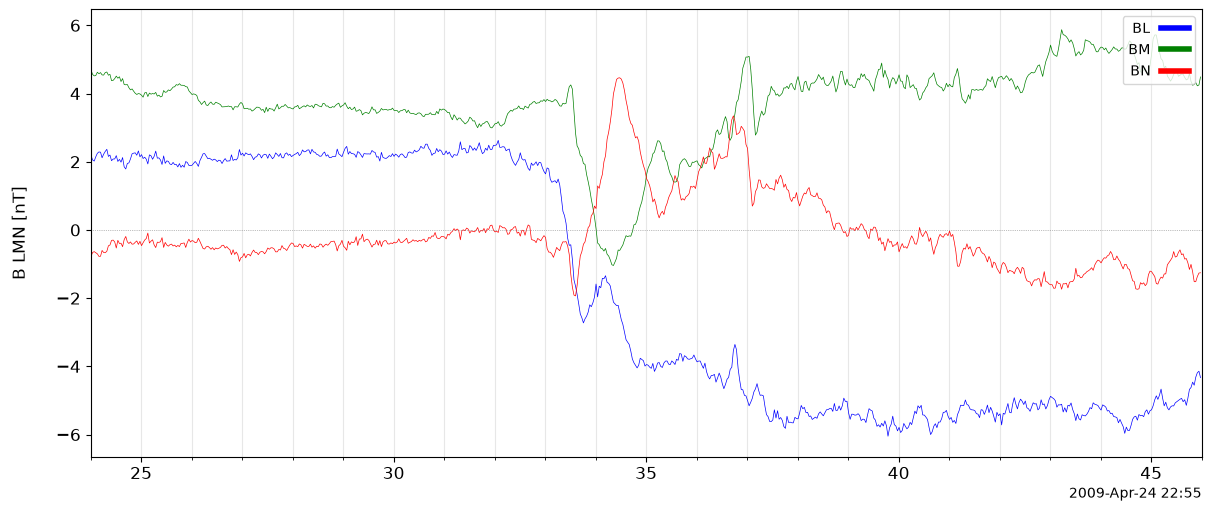

In [133]:
R = np.vstack([L_ax, M_ax, N]) # 3x3 rotation matrix with stacked vectors L, M, N as rows
B_lmn = B @ R.T # each row becomes [B·L, B·M, B·N]

store_data('kgy_lmag_lmn', data={'x': t, 'y': B_lmn})
options('kgy_lmag_lmn', 'legend_names', ['BL', 'BM', 'BN'])
options('kgy_lmag_lmn', 'color', ['b', 'g', 'r'])
options('kgy_lmag_lmn', 'ytitle', 'B LMN [nT]')

fig, ax = tplot('kgy_lmag_lmn',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)
ax.axhline(0, color='grey', lw=0.5, ls=':') 
ax.xaxis.set_minor_locator(mdates.SecondLocator())
ax.grid(which='both', axis='x', alpha=0.3)
plt.show()

B_L changes sign, suggesting crossing occured, as expected. Decent agreement with fig. 2(h) in Ogino 2026. Great success!

Now plotting electron energy spectrogram using ESA-S2. The eflux file contains data for the differential energy flux across the whole interval, with one row per second and 14 energies:

(24,) (24, 14) (24, 14)


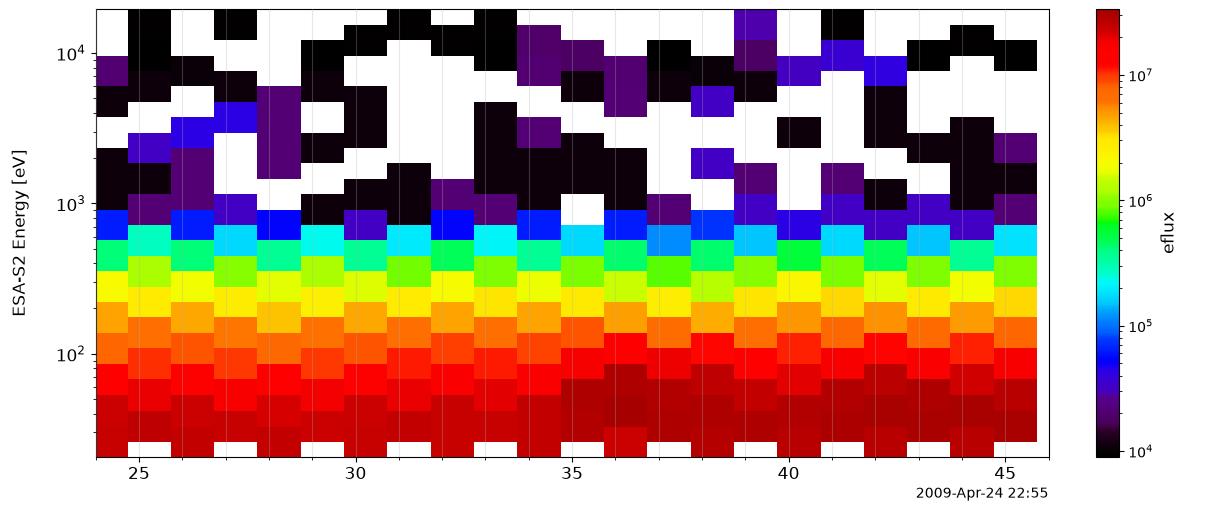

In [134]:
import glob

# find files by pattern
f_ef = glob.glob('kaguya_data/esa2_eflux*')[0]
f_en = glob.glob('kaguya_data/esa2_energy*')[0]

# read the time column 
t_e    = np.array(time_double(np.loadtxt(f_ef, usecols=0, dtype=str))) # column 0 of eflux file is time string, as array
eflux  = np.loadtxt(f_ef, usecols=range(1, 15)) # 14 flux values, skipping time
energy = np.loadtxt(f_en)

# check shape to make sure time, flux and energy have same number of rows for plotting
print(t_e.shape, eflux.shape, energy.shape)

#store data: x is times (horizontal axis), v is energies (vertical axis), y is fluxes (colur)
store_data('kgy_esa2_eflux', data={'x': t_e, 'y': eflux, 'v': energy})
# draw as spectrogram
options('kgy_esa2_eflux', 'spec', True)
#log scales
options('kgy_esa2_eflux', 'ylog', True)
options('kgy_esa2_eflux', 'zlog', True)
#titles
options('kgy_esa2_eflux', 'ytitle', 'ESA-S2 Energy [eV]')
options('kgy_esa2_eflux', 'ztitle', 'eflux')

fig, axes = tplot('kgy_esa2_eflux',
                  trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                  display=False, return_plot_objects=True)

for ax in np.atleast_1d(axes):
    ax.xaxis.set_minor_locator(mdates.SecondLocator())
    ax.grid(which='both', axis='x', alpha=0.3)
    ax.set_axisbelow(False)
plt.show()

On the spectrogram, the height is energy, and the colour is flux. The instrument up-sweep and down-sweep voltage steps are not matched, so consecutive strips have cells at slightly different heights. Gaps originate from low counts at high energies above 1 keV; the paper truncates aboce and below. We can re-plot with truncation and also apply viridis colour scheme:

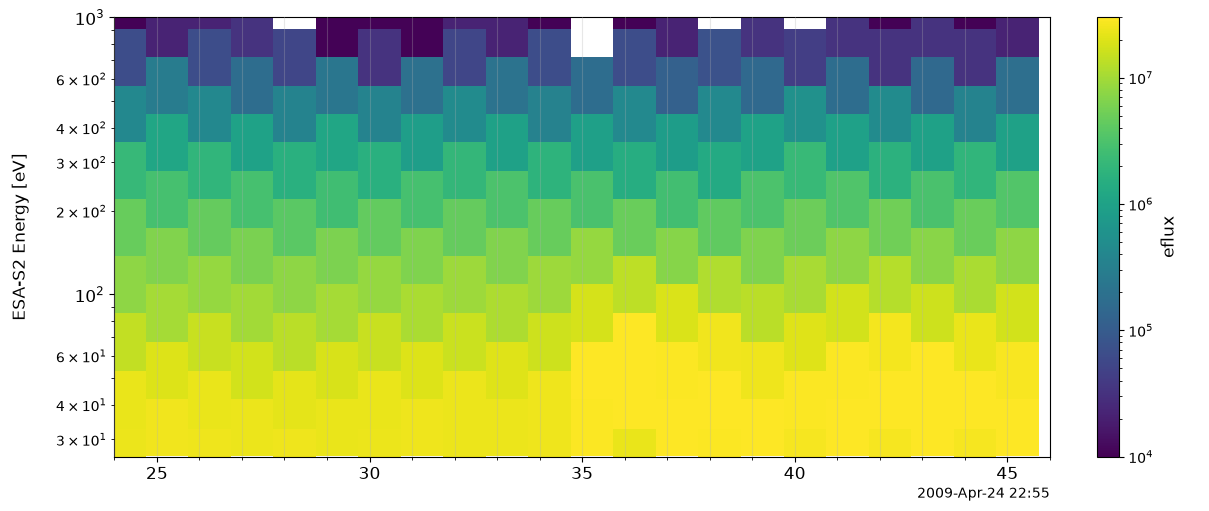

In [135]:
options('kgy_esa2_eflux', 'yrange', [20, 1000]) # truncate energy
options('kgy_esa2_eflux', 'zrange', [1e4, 3e7]) # colour scale limits to match Ogino
options('kgy_esa2_eflux', 'colormap', 'viridis')
options('kgy_esa2_eflux', 'yrange', [26, 1000])

fig, axes = tplot('kgy_esa2_eflux',
                  trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                  display=False, return_plot_objects=True)

for ax in np.atleast_1d(axes):
    ax.xaxis.set_minor_locator(mdates.SecondLocator())
    ax.grid(which='both', axis='x', alpha=0.3)
    ax.set_axisbelow(False)
plt.show()

Ogino et al. state that electron energisation can be identified from this spectrogram. Not convinced? We can check this claim by dividing the flux for each second during the crossing by the average flux during the unperturbed period, for each energy. Each half-sweep has 16 energy steps, and the file keeps only 14 (lowest energies are excluded, since authors claim that electrons below 20 eV cannot be measured reliably).

Question: how does uncorrected spacecraft potential affect measurements? How to estimate SELENE potential?

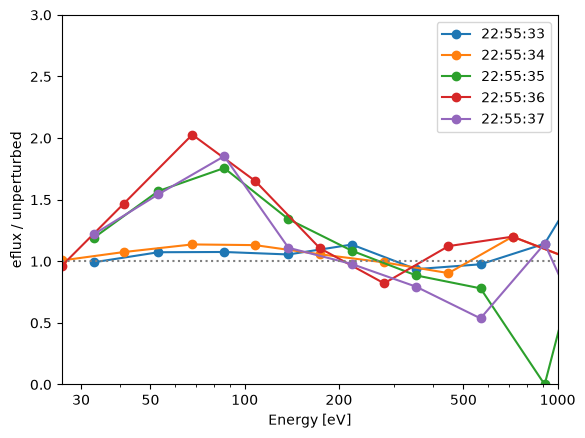

In [136]:
import matplotlib.ticker as mticker

# define unperturbed region from 24 seconds to 32 seconds
unp = (t_e >= time_double('2009-04-24/22:55:24')) & (t_e < time_double('2009-04-24/22:55:32'))

# make plots
fig, ax = plt.subplots()
for ts in ['22:55:33', '22:55:34', '22:55:35', '22:55:36', '22:55:37']:
    i = np.argmin(np.abs(t_e - time_double('2009-04-24/' + ts)))
    same = unp & (energy[:, 0] == energy[i, 0]) # is unp the same sweep as the tested row?
    ratio = eflux[i] / np.nanmean(eflux[same], axis=0)
    ax.plot(energy[i], ratio, marker='o', label=ts)

ax.axhline(1, color='grey', ls=':')
ax.set_xscale('log'); ax.set_xlim(26, 1000)
ax.set_xlabel('Energy [eV]'); ax.set_ylabel('eflux / unperturbed')
ax.set_xticks([30, 50, 100, 200, 500, 1000])
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_ylim(0, 3)
ax.legend(); plt.show()

Conclusion: during 35-37 s, ESA-S2 measured about 1.5-2 times more electrons at 50-100 eV compared to the unperturbed period. We attribute the dip near 1 keV due to noise (fluctuations of a few counts give large ratio fluctuations for small sample size). This supports energisation observations.

Next try velocity distribution function (VDF) slices. We look first at the middle of the crossing (roughly at 35 seconds, reading off time (2) in Ogino to reproduce figures 2(m) and (n)). 

First we create a scatter plot in the Vy-Vz plane of electron velocity coloured by the distribution function:

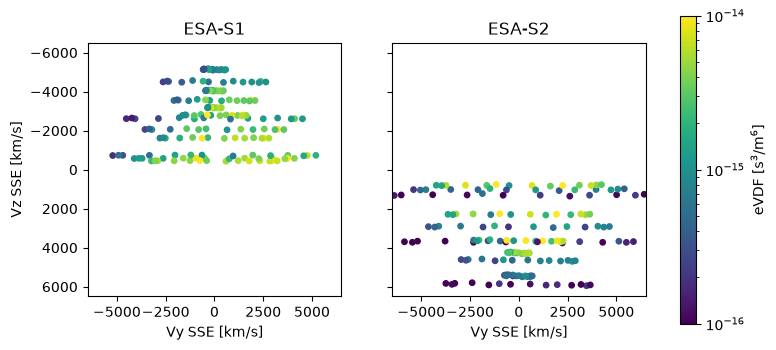

In [137]:
from matplotlib.colors import LogNorm

# use 22:55:35 for (2) in Ogino
t_str = '20090424225535'
d1 = np.loadtxt(f'kaguya_data/esa1_df_{t_str}.txt')
d2 = np.loadtxt(f'kaguya_data/esa2_df_{t_str}.txt')

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, d, name in zip(axes, [d1, d2], ['ESA-S1', 'ESA-S2']):
    sc = ax.scatter(d[:, 1], d[:, 2], c=d[:, 3], s=15, # 0 for x, 1 for y, 2 for z
                    norm=LogNorm(1e-16, 1e-14), cmap='viridis')
    ax.set_title(name)
    ax.set_xlabel('Vy SSE [km/s]')
    ax.set_aspect('equal')
axes[0].set_ylabel('Vz SSE [km/s]')
axes[0].set_xlim(-6500, 6500); axes[0].set_ylim(6500, -6500) # Vz flipped to match Ogino
fig.colorbar(sc, ax=axes, label='eVDF [s$^3$/m$^6$]')
plt.show()

Each point is one row in the file (i.e. one direction at one energy). Each sensor only covers half of the plane. To get from this to the fan plot, we need to take a slice in the Vy-Vz plane instead of a projection, and fit a Maxwellian to the data somehow...

First we take a slice, i.e. keep only bins whose velocity lie close to Vy-Vz plane:

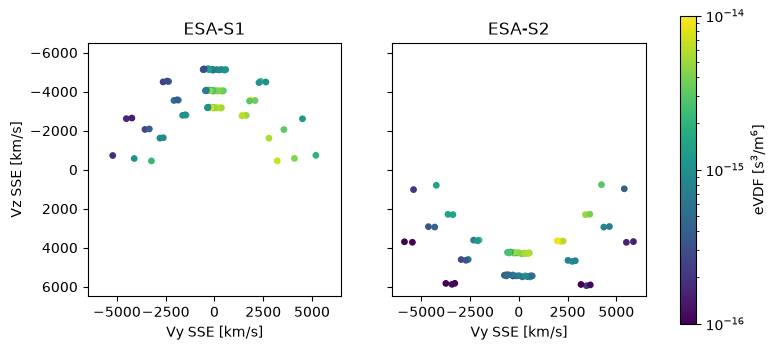

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)

for ax, d, name in zip(axes, [d1, d2], ['ESA-S1', 'ESA-S2']):
    vmag = np.linalg.norm(d[:, :3], axis=1) # speed of each bin
    near = np.abs(d[:, 0]) / vmag < np.sin(np.radians(20)) # within \pm 20 degrees of the Vy–Vz plane
    sc = ax.scatter(d[near, 1], d[near, 2], c=d[near, 3], s=15, # c sets colour, d sets size
                    norm=LogNorm(1e-16, 1e-14), cmap='viridis')
    ax.set_title(name)
    ax.set_xlabel('Vy SSE [km/s]')
    ax.set_aspect('equal')
    
axes[0].set_ylabel('Vz SSE [km/s]')
axes[0].set_xlim(-6500, 6500); axes[0].set_ylim(6500, -6500) # Vz flipped to match Ogino
fig.colorbar(sc, ax=axes, label='eVDF [s$^3$/m$^6$]')
plt.show()

To draw the fan, need to add energy edges and angular range to bin to find sectors.

Problem: Fig. 2(m) and (n) are rotated?

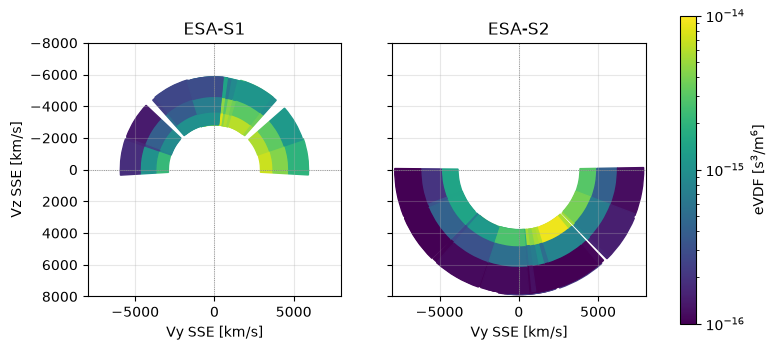

In [139]:
from matplotlib.patches import Wedge
from matplotlib.cm import ScalarMappable

norm = LogNorm(1e-16, 1e-14)
cmap = plt.get_cmap('viridis')
r_step   = 1.6 # energy ratio between steps
half_ang = 11.25 # half of a 22.5 degree sector

def draw_fan(ax, d, max_tilt=20):
    v = d[:, :3]
    vmag = np.linalg.norm(v, axis=1)
    near = np.abs(v[:, 0]) / vmag < np.sin(np.radians(max_tilt)) # the slice in Vy-Vz plane

    #draw energy bins (display choice)
    for vy, vz, vm, f in zip(v[near, 1], v[near, 2], vmag[near], d[near, 3]):
        r_in  = vm / r_step**0.25 # inner edge of energy bin; 0.25 from 0.5 (geometric mean from log scale) x 0.5 (velocity scales like \sqrt energy)
        r_out = vm * r_step**0.25 # outer edge
        ang = np.degrees(np.arctan2(vz, vy)) # direction of the bin in the Vy–Vz plane
        ax.add_patch(Wedge((0, 0), r_out, ang - half_ang, ang + half_ang,
                           width=r_out - r_in, color=cmap(norm(f))))

t_str = '20090424225535'
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, sensor, name in zip(axes, ['esa1', 'esa2'], ['ESA-S1', 'ESA-S2']):
    d = np.loadtxt(f'kaguya_data/{sensor}_df_{t_str}.txt')
    draw_fan(ax, d)
    ax.set_title(name); ax.set_xlabel('Vy SSE [km/s]'); ax.set_aspect('equal')

axes[0].set_ylabel('Vz SSE [km/s]')
for ax in axes:
    ax.axhline(0, color='grey', lw=0.6, ls=':') # horizontal line through Vz = 0
    ax.axvline(0, color='grey', lw=0.6, ls=':') # vertical line through Vy = 0
    ax.grid(alpha=0.3)
axes[0].set_xlim(-8000, 8000); axes[0].set_ylim(8000, -8000)

fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes, label='eVDF [s$^3$/m$^6$]')
plt.show()

Why are my fans rotated?? To understand, try the Maxwellian fit...

Can fit least squares in ln(f), where f is a shifted Maxwellian, to estimate the fitting parameters (density, 3 dimensions of bulk velocity, temperature):

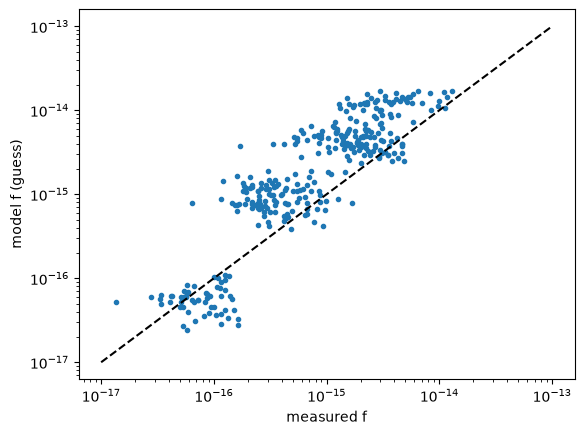

In [140]:
# define constants
me, e = 9.109e-31, 1.602e-19

def maxwellian(v, n, ux, uy, uz, T_eV):
    """
    v: velocities of all bins, array of shape (N,3) in m/s; 
    n: density in m^-3;
    u: plasma bulk velocity in m/s, with 3 components;
    T: temperature in eV.
    
    Returns distribution fn f in s^3/m^6.
    """
    kT = T_eV * e # temperature as an energy in J
    dv2 = np.sum((v - np.array([ux, uy, uz]))**2, axis=1)   # |v - u|^2 for every bin
    return n * (me / (2*np.pi*kT))**1.5 * np.exp(-me * dv2 / (2*kT))

# try 22:55:25
t_str = '20090424225525'
d = np.vstack([np.loadtxt(f'kaguya_data/esa1_df_{t_str}.txt'),
               np.loadtxt(f'kaguya_data/esa2_df_{t_str}.txt')])
v = d[:, :3] * 1e3 #km/s to m/s
f = d[:, 3]

#guesses for params
f_guess = maxwellian(v, 5.7e6, -400e3, 0, 0, 20)

plt.loglog(f, f_guess, '.')
plt.plot([1e-17, 1e-13], [1e-17, 1e-13], 'k--') # line where model = measurement
plt.xlabel('measured f'); plt.ylabel('model f (guess)')
plt.show()

Clearly this fit is bad. Let us create a better estimate of fitting params using least squares (see OneNote):

In [141]:
vk = d[:, :3] # velocities in km/s
good = f > 0  # drop empty bins for log
vk, lf = vk[good], np.log(f[good])

A = np.column_stack([np.ones(len(vk)), vk, np.sum(vk**2, axis=1)])
coef, *_ = np.linalg.lstsq(A, lf, rcond=None) # least squares
a, b, c = coef[0], coef[1:4], coef[4]

vth2 = -1 / c # thermal speed squared in (km/s)^2
u    = -b / (2 * c) # bulk velocity in km/s
T_eV = me * vth2 * 1e6 / (2 * e) # ×1e6 converts (km/s)^2 to (m/s)^2
n    = np.exp(a + 1.5*np.log(np.pi * vth2 * 1e6) + (u @ u) / vth2)

print('u [km/s]:', u.round(0))
print('T [eV]:', T_eV.round(1), '& n [cm^-3]:', (n / 1e6).round(2))

u [km/s]: [-29. 338. 201.]
T [eV]: 25.5 & n [cm^-3]: 1.71


Fascinating-- almost no flow velocity on the x-axis. So how can it be SSE????

Replot with calculated params:

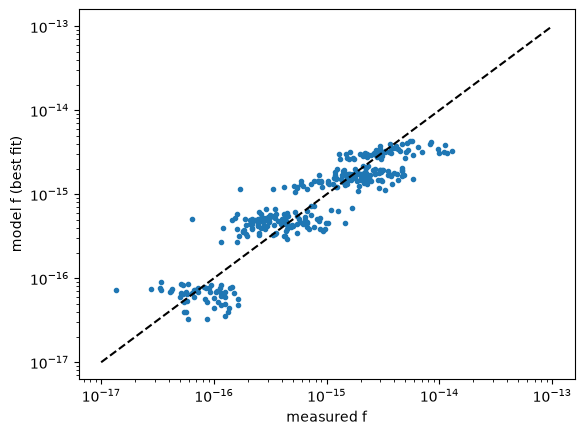

In [142]:
f_fit = maxwellian(v, n, *(u * 1e3), T_eV)

plt.loglog(f, f_fit, '.')
plt.plot([1e-17, 1e-13], [1e-17, 1e-13], 'k--')
plt.xlabel('measured f'); plt.ylabel('model f (best fit)')
plt.show()

This still looks bad???

Try to determine slice using slice2d_plot instead of scatter plot. We need to write a Kaguya wrapper first:

18-Oct-26 17:33:35: Finished slice at 2009-04-24 22:55:35.000000


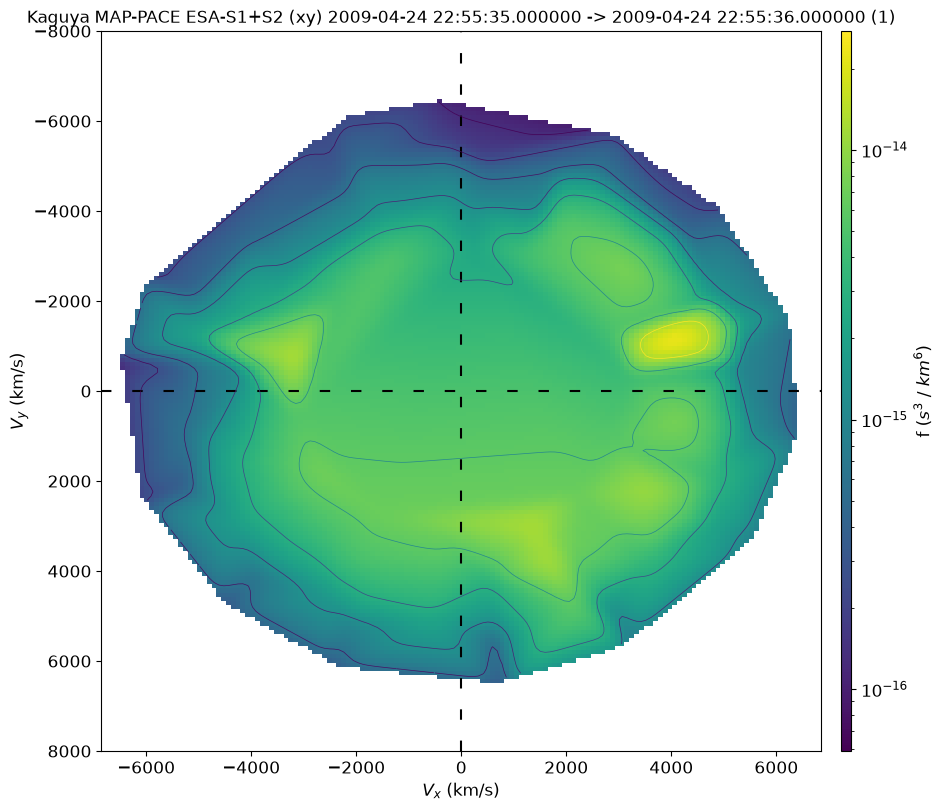

In [154]:
from pyspedas import slice2d, slice2d_plot

MASS_E = 5.6856e-6 #electron mass in eV/(km/s)^2

def kgy_dist(t_str):

    #load both sensors and stack S1 on top of S2 rows
    d = np.vstack([np.loadtxt(f'kaguya_data/{s}_df_{t_str}.txt') for s in ['esa1', 'esa2']])

    #slice velocities in km/s, and use norm to find speed
    v = d[:, :3]
    speed = np.linalg.norm(v, axis=1)

    #find how many energies does each direction have by looking at how many times velocity drops
    nE = np.argmax(np.diff(speed) < 0) + 1

    #find total number of directions
    nD = len(d) // nE

    #rearranges column into SPEDAS layout:
    to3d = lambda x: x.reshape(nD, nE).T[:, :, None] # -> shape (energy, direction, 1)
    f = to3d(d[:, 3])
    t0 = time_double(f'{t_str[:4]}-{t_str[4:6]}-{t_str[6:8]}/{t_str[8:10]}:{t_str[10:12]}:{t_str[12:]}')
    return {'data':   f,
            'energy': to3d(0.5 * MASS_E * speed**2), # eV
            'theta':  to3d(np.degrees(np.arcsin(v[:, 2] / speed))), # elevation, deg
            'phi':    to3d(np.degrees(np.arctan2(v[:, 1], v[:, 0])) % 360), # azimuth, deg
            'dtheta': np.full(f.shape, 22.5), 'dphi': np.full(f.shape, 22.5),
            'bins':   np.ones(f.shape, dtype=int),
            'mass': MASS_E, 'charge': -1.0,
            'project_name': 'Kaguya', 'spacecraft': 'MAP-PACE',
            'data_name': 'ESA-S1+S2', 'species': 'e',
            'units_name': 'df_km',
            'start_time': t0, 'end_time': t0 + 1.0}

dist = [kgy_dist('20090424225535')] #dist takes list
sl = slice2d(dist, time='2009-04-24/22:55:35', window=1, rotation='xy', interpolation='2d') #interpolation choices: geometric (wedges) or 2d (smoothed contours)
slice2d_plot(sl, colormap='viridis', yrange=[8000, -8000])